<a href="https://colab.research.google.com/github/josthindwa-cenacle/COU07506-labs/blob/main/COU07506_WEEK01_240647424521.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506: Digital Signal Processing
## Week 1 - Lab 0: Setting up the DSP Labaratory
* **Name:** JOSHUA P. THINDWA
* **Registration Number:** 240647424521
* **Class:** Beng24COE
* **Date:** 25 Novemer 2026
* **GitHub repository:**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

### Pre-lab question
**three devices used today that contain DSP, and for each one
signal it processes.**



### Task 1.1 - First notebook

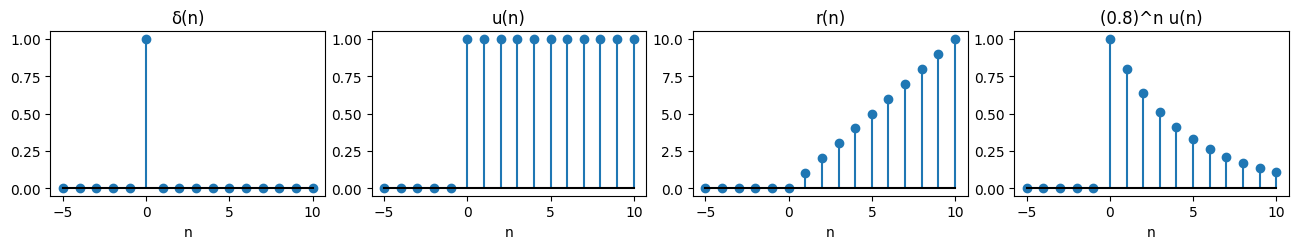

In [ ]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float) # unit impulse
step = (n >= 0).astype(float) # unit step ramp = n * step # unit ramp
expo = 0.8**n * step # real exponential
fig, axes = plt.subplots(1, 4, figxsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
  ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
  ax.stem(n, x, basefmt="k-")
  ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

### Task 1.2- Changing parameters


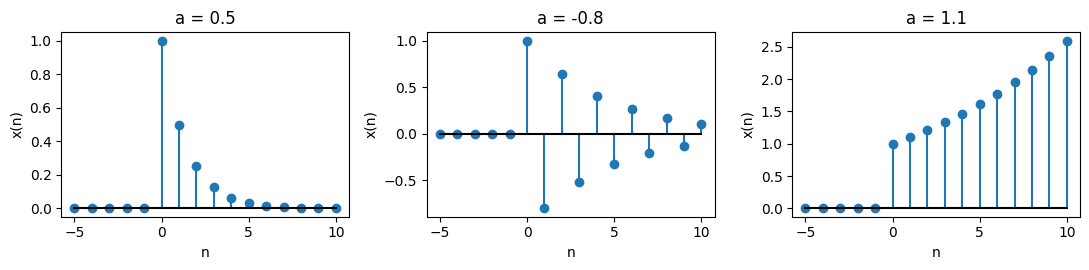

In [ ]:
# 1. Plot for (𝑎)𝑛𝑢(𝑛) for 𝑎 = 0.5, 𝑎 = −0.8 and 𝑎 = 1.1
n = np.arange(-5, 11)
step = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a ** n) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("x(n)")
plt.tight_layout()
plt.show()

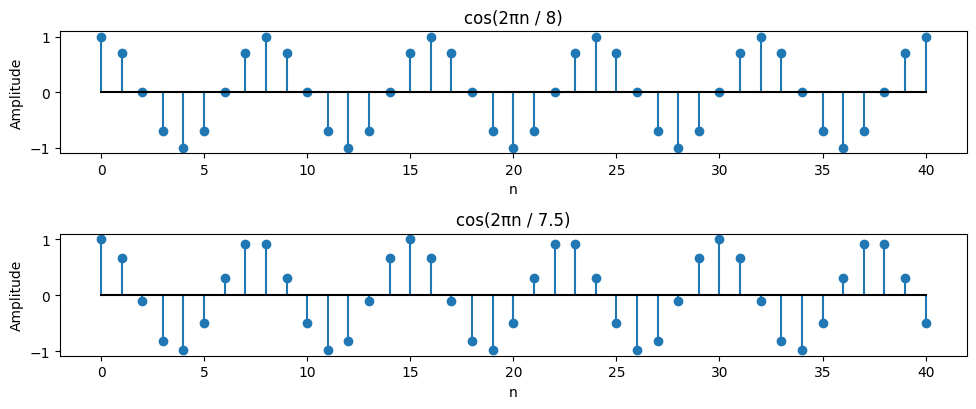

In [ ]:
# 2. Plot for cos(2𝜋𝑛/8) and cos(2𝜋𝑛/7.5) for 0 ≤ 𝑛 ≤ 40
n40 = np.arange(0, 41)
x1 = np.cos(2 * np.pi * n40 / 8)
x2 = np.cos(2 * np.pi * n40 / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.2))
axes[0].stem(n40, x1, basefmt="k-")
axes[0].set_title("cos(2πn / 8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n40, x2, basefmt="k-")
axes[1].set_title("cos(2πn / 7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

Cos(2𝜋n/8) repeats.

### Task 1.3 - Working with audio

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ffmpeg -y -i "/Temeke 3.m4a" "/Temeke dsp 1.WAV"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

fs = 44100 Hz, duration = 8.38 s, samples = 369664


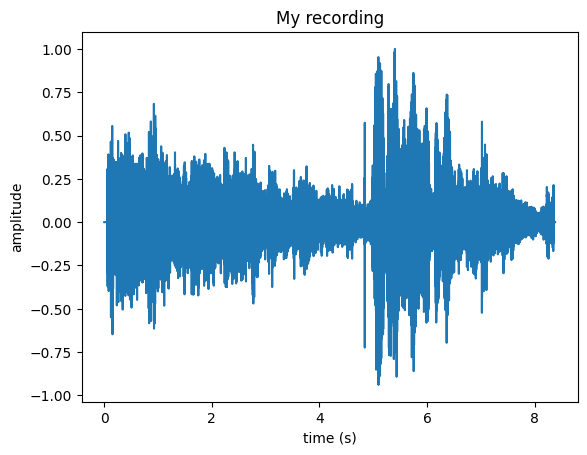

In [ ]:
import os
from IPython.display import Audio; Audio(x, rate=fs)
fname = "/Temeke dsp 1.WAV"
if os.path.exists(fname):
	fs, x = wavfile.read(fname)
	if x.ndim > 1: # stereo -> mono
		x = x.mean(axis=1)
	x = x / np.max(np.abs(x))    # normalise to [-1, 1]
else:
	fs = 16000
	t = np.arange(0, 2, 1/fs)
	x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()





Loaded your voice recording successfully!
fs = 44100 Hz, duration = 8.38 s, samples = 369664


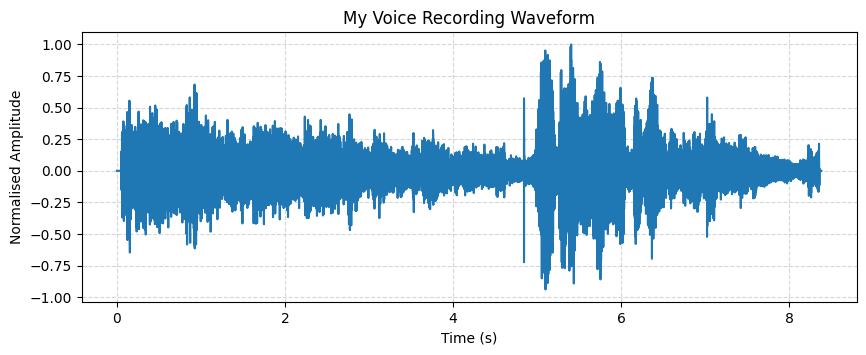

In [ ]:
import os
from IPython.display import Audio

# Point to your Google Drive folder (or use "my_voice.wav" if uploaded directly to Colab)
fname = "/Temeke dsp 1.WAV"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                  # Convert stereo (2 channels) -> mono (1 channel)
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))       # Normalise amplitude to [-1, 1]
    print("Loaded your voice recording successfully!")
else:                               # Fallback test signal if file isn't uploaded yet
    print("Audio file not found — running fallback 440 Hz test signal.")
    fs = 16000
    t_fb = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t_fb) * np.exp(-t_fb)

# Create time axis in seconds and print audio properties
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

# Plot the waveform
plt.figure(figsize=(10, 3.5))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Normalised Amplitude")
plt.title("My Voice Recording Waveform")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Display interactive audio player
Audio(x, rate=fs)